# All Imports

In [73]:
import requests
import pandas as pd
import plotly.express as px
import seaborn as sns

# Custom Theme

In [164]:
import plotly.graph_objects as go
import plotly.io as pio

space_template = go.layout.Template(
    layout = go.Layout(
        paper_bgcolor = "#1e1e24",
        plot_bgcolor = "#1e1e24",

        colorway = ["#92140c", "#ffcf99"],

        font = dict(
            family = "Georgia, sans-serif",
            size = 12,
            color = "#fff8f0"
        ),

        title=dict(
            font=dict(size=20, color="#fff8f0"),
            x=0.5,
            xanchor="center",
        ),

        xaxis = dict(
            gridcolor = "#fff8f0",      
            linecolor = "#fff8f0",     
            showgrid = False
        ),

        yaxis = dict(
            gridcolor = "#fff8f0",
            linecolor = "#fff8f0",
            showgrid = False
        ),
    )
)

pio.templates["space_template"] = space_template
pio.templates.default = "space_template"

# Creating a fields df to look at column names

In [74]:
url = "https://ssd-api.jpl.nasa.gov/sbdb_query.api"
r = requests.get(url, params={"info": "field"})
print(r.status_code)

info = r.json()
rows = []
for group in info["info"]["field"].values():
    rows.extend(group["list"])

fields_df = pd.DataFrame(rows)
fields_df[["name", "description"]]
fields_df.to_csv("fields.csv", index=False)
fields_df[fields_df["name"] == "diameter"]

200


,name,description,units,title
67,diameter,object diameter (from equivalent sphere),km,diameter


# Asteroid DF

In [75]:
params = {
    "fields": "full_name,diameter,q,e,a,i,first_obs,last_obs,data_arc",  
    "sb-kind": "a",                                          
}
response = requests.get(url, params=params)
response.raise_for_status() 
result = response.json()     
asteroids = pd.DataFrame(result["data"], columns=result["fields"])
asteroids.head()

,full_name,diameter,q,e,a,i,first_obs,last_obs,data_arc
0,1 Ceres (A801 AA),939.4,2.545,0.0797,2.766,10.59,1995-01-05,2021-01-28,9520
1,2 Pallas (A802 FA),513,2.131,0.2307,2.77,34.93,1804-08-27,2025-12-14,80828
2,3 Juno (A804 RA),246.596,1.988,0.2557,2.671,12.99,1804-10-17,2026-04-13,80897
3,4 Vesta (A807 FA),522.77,2.148,0.0902,2.361,7.14,1950-09-23,2021-03-17,25743
4,5 Astraea (A845 XA),106.699,2.093,0.1876,2.577,5.36,1845-12-15,2025-10-19,65687


In [76]:
asteroids = asteroids.dropna(subset=["full_name", "diameter", "q", "e", "a", "i", "first_obs", "last_obs", "data_arc"])

In [122]:
asteroids["first_obs_year"] = pd.to_numeric(asteroids["first_obs"].str[:4], errors="coerce")
asteroids["last_obs_year"] = pd.to_numeric(asteroids["last_obs"].str[:4], errors="coerce")
asteroids["diameter"] = pd.to_numeric(asteroids["diameter"], errors="coerce")
asteroids["q"] = pd.to_numeric(asteroids["q"], errors="coerce")
asteroids["type"] = "asteroid"
asteroids = asteroids.sort_values(by="first_obs_year", ascending=True)

# Comets DF

In [78]:
params_1 = {
    "fields":"full_name,diameter,e,q,a,i,first_obs,last_obs,data_arc",
    "sb-kind" : "c",
    "limit" : 1000
}

response = requests.get(url, params=params_1)
response.raise_for_status()
result_1 = response.json()
comets = pd.DataFrame(result_1["data"], columns=result_1["fields"])
comets.head()

,full_name,diameter,e,q,a,i,first_obs,last_obs,data_arc
0,1P/Halley,11.0,0.9679,0.575,17.93,162.19,1835-08-21,1994-01-11,57852
1,2P/Encke,4.8,0.8470,0.339,2.218,11.34,2018-11-05,2026-11-06,2923
2,3D/Biela,NaN,0.7513,0.879,3.535,13.22,NaN,NaN,NaN
3,4P/Faye,3.54,0.5845,1.578,3.798,8.16,2013-05-23,2023-03-25,3593
4,5D/Brorsen,NaN,0.8098,0.590,3.101,29.38,NaN,NaN,NaN


In [89]:
comets = comets.dropna(subset=["full_name", "diameter", "q", "e", "a", "i", "first_obs", "last_obs", "data_arc"])
comets.head()
print(comets.shape)

(98, 12)


In [123]:
comets["first_obs_year"] = pd.to_numeric(comets["first_obs"].str[:4], errors="coerce")
comets["last_obs_year"] = pd.to_numeric(comets["last_obs"].str[:4], errors="coerce")
comets["diameter"] = pd.to_numeric(comets["diameter"], errors="coerce")
comets["q"] = pd.to_numeric(comets["q"], errors="coerce")
comets["type"] = "comet"
comets = comets.sort_values(by="first_obs_year", ascending=True)

# Building Combined DF

In [114]:
total_data = pd.concat([asteroids, comets], ignore_index=True)
total_data["data_arc"] = pd.to_numeric(total_data["data_arc"], errors="coerce")
total_data["type"].value_counts()

type
asteroid    139578
comet           98
Name: count, dtype: int64

In [109]:
type(total_data["q"])
print (total_data["q"].describe())

count    139676.000000
mean          2.400981
std           0.523853
min           0.082000
25%           2.070000
50%           2.369000
75%           2.688000
max          40.970000
Name: q, dtype: float64


In [157]:

fig = px.scatter(
    total_data, 
    x = "diameter",
    log_x=True,
    y = "q",
    animation_frame = "first_obs_year",
    animation_group = "full_name",
    hover_name = "full_name",
    color = "type",
    category_orders = {"first_obs_year": sorted(total_data["first_obs_year"].dropna().unique())},
    # size = "data_arc",
    template = "space_template",
    range_y = [0,41]
)

fig.update_layout(
    title = "Asteroid Diameter vs Perihelion Distance",
    xaxis_title = "Diameter (km)",
    yaxis_title = "Perihelion Distance (AU)",
    legend_title = "Asteroid Name",
    font=dict(
        family="Times, sans-serif",
        size=12,
        color="white"
    ),
    legend=dict(orientation="v"),
)

fig.show()

# Looking at Semi-Major Axis vs. Perihelion

In [144]:
total_data["e"].describe()

count     139676
unique      4977
top       0.1320
freq          96
Name: e, dtype: object

In [147]:
total_data.dtypes
total_data["e"] = pd.to_numeric(total_data["e"])

In [175]:
years = sorted(total_data["first_obs_year"].dropna().unique())

placeholders = pd.MultiIndex.from_product(
    [years, ["asteroid", "comet"]], names=["first_obs_year", "type"]
).to_frame(index=False)

placeholders["full_name"] = "placeholder_" + placeholders["type"] + "_" + placeholders["first_obs_year"].astype(str)
placeholders["diameter"] = 1   # needs a size value, but nothing is drawn since e and q are empty

plot_df = pd.concat([total_data, placeholders], ignore_index=True)

In [177]:

fig = px.scatter(
    plot_df,
    x = "e",
    y = "q",
    animation_frame = "first_obs_year",
    animation_group = "full_name",
    hover_name = "full_name",
    color = "type",
    category_orders = {"first_obs_year": years},
    size = "diameter",
    template = "space_template",
    range_y = [0,41],
    range_x = [0,1],
    size_max = 30
)

fig.update_layout(
    title = "Asteroids and Comets Closer to Earth Discovered Earlier in History",
    xaxis_title = "Semi-Major Axis (AU)",
    yaxis_title = "Perihelion Distance (AU)",
    legend_title = "Object Type",
    legend=dict(orientation="v")
)

fig.update_traces(marker=dict(sizemin=5))

fig.show()

/var/folders/v1/hryn5p353mzgt1vxf4q_fckh0000gn/T/ipykernel_39951/1335278448.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="type", y="q", data=total_data, palette=palette)


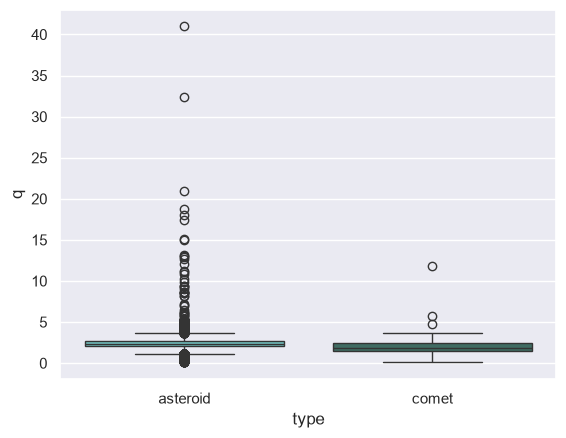

In [ ]:
sns.set(style="darkgrid")
sns.boxplot(x="type", y="q", data=total_data, palette=palette, )
figsize = (10, 6)